# When one class is rare

Fraud, disease, defects, intrusions: the cases worth detecting are usually rare, and rarity breaks the habits of [Evaluating a classifier](classification_metrics.ipynb). A model can be right 98% of the time and useless; a curve can look excellent and hide thousands of false alarms. One such problem follows, from the misleading numbers to a model and a threshold chosen for what they are for.

## The data

The *mammography* dataset, from OpenML: 11,183 regions of mammograms, each described by six numbers computed from the image, and labelled as showing a microcalcification or not (Woods and others, 1993): tiny deposits of calcium that radiologists look for, because a cluster of them can be an early sign of breast cancer. It is a classic benchmark for rare classes, used, among others, in the paper that introduced the SMOTE technique mentioned below. Its documentation on OpenML says little more: the six features have no names, only `attr1` to `attr6`.

In [ ]:
from sklearn.datasets import fetch_openml

mammography = fetch_openml(name="mammography", version=1, as_frame=True)
X = mammography.data
y = (mammography.target == "1").astype(int).rename("calcification")
y.value_counts(), y.mean().round(4)

(calcification
 0    10923
 1      260
 Name: count, dtype: int64,
 np.float64(0.0232))

A stratified split, so that the 260 positive regions are shared in the same proportion ([Overfitting and the train/test split](../ml-fundamentals/overfitting_and_the_split.ipynb#stratified-splits)); with so few, a plain random split could give the test set noticeably more or fewer of them:

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
y_train.sum(), y_test.sum()

(np.int64(208), np.int64(52))

## The accuracy of answering "no"

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

accuracy_score(y_test, DummyClassifier().fit(X_train, y_train).predict(X_test))

0.9767545820295038

97.7%, without finding a single calcification. With 2.3% of positives, any accuracy below 97.7% is worse, by this measure, than doing nothing (the model chosen at the end is one of them), and any accuracy above it hides how many positives were found. Accuracy is the wrong measure here, and the baseline is the first number to compute.

## Two models, measured properly

A logistic regression and a random forest, measured by 5-fold cross-validation on the training rows. `cross_val_predict` gives each training row the probability predicted by a model that didn't see it, so every measure, at any threshold, can be computed from one set of predictions:

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1),
}
probabilities = {name: cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
                 for name, model in models.items()}
pd.DataFrame({
    name: {
        "accuracy": accuracy_score(y_train, p >= 0.5),
        "precision": precision_score(y_train, p >= 0.5),
        "recall": recall_score(y_train, p >= 0.5),
        "ROC AUC": roc_auc_score(y_train, p),
        "average precision": average_precision_score(y_train, p),
    }
    for name, p in probabilities.items()
}).T.round(3)

,accuracy,precision,recall,ROC AUC,average precision
logistic regression,0.984,0.8,0.404,0.906,0.593
random forest,0.987,0.9,0.519,0.939,0.726


Both models beat the baseline's 97.7% accuracy by less than a point and a half, which says almost nothing, and at the default threshold they find only 40% and 52% of the calcifications. Their ROC AUC, 0.91 and 0.94, looks excellent. Their average precision, 0.59 and 0.73, is more sober, and separates the two models more clearly. The forest is better by every measure.

## ROC against precision and recall

The ROC curve of [Evaluating a classifier](classification_metrics.ipynb#roc-curve-and-auc) plots the recall against the *false positive rate*: false alarms divided by all the negatives. With 8,700 negatives, a thousand false alarms are a rate of 0.11, which looks small on that curve. The **precision–recall curve** plots precision instead, false alarms against the alarms raised, which is what a person who has to check each alarm experiences. Its area, the **average precision**, would be 0.023 for a model that guesses, the share of positives, not 0.5 as for the ROC:

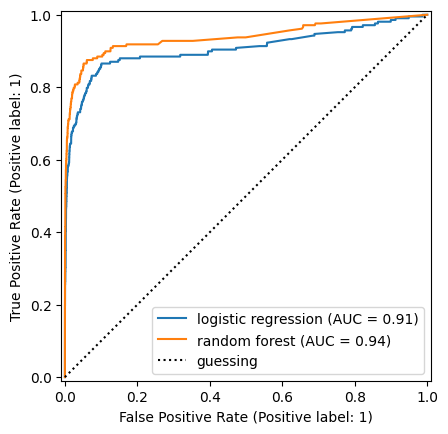

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

for name, p in probabilities.items():
    RocCurveDisplay.from_predictions(y_train, p, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k:", label="guessing")
plt.legend()
plt.show()

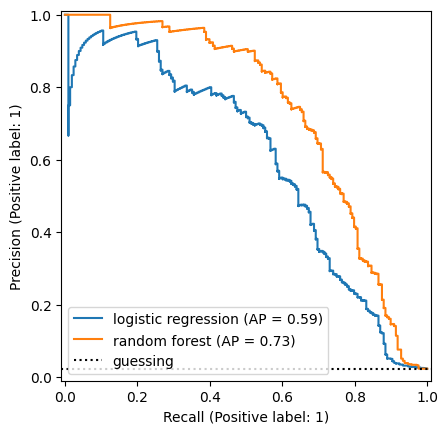

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

for name, p in probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_train, p, name=name, ax=plt.gca())
plt.axhline(y_train.mean(), color="k", linestyle=":", label="guessing")
plt.legend()
plt.show()

On the ROC curve both models rise steeply and look much alike. On the precision–recall curve, the difference and the difficulty are plain: to find 80% of the calcifications, the forest's precision is about 0.4, and the logistic regression's about 0.2, so that most of the regions flagged would be normal tissue. The precision–recall view is the one to show anyone who will act on the alarms.

## Choosing a threshold

The default threshold of 0.5 assumes that both errors cost the same. In screening, a missed calcification costs far more than a second look at a normal region, so the threshold is lowered until enough cases are found. The forest, at several thresholds, on its cross-validated probabilities:

In [ ]:
forest_probabilities = probabilities["random forest"]
pd.DataFrame({
    threshold: {
        "regions flagged": int((forest_probabilities >= threshold).sum()),
        "precision": precision_score(y_train, forest_probabilities >= threshold),
        "recall": recall_score(y_train, forest_probabilities >= threshold),
    }
    for threshold in (0.5, 0.3, 0.2, 0.1, 0.05)
}).T.rename_axis("threshold").round(3)

,regions flagged,precision,recall
threshold,,,
0.50,120.0,0.900,0.519
0.30,183.0,0.738,0.649
0.20,246.0,0.602,0.712
0.10,387.0,0.429,0.798
0.05,612.0,0.288,0.846


At 0.5 the forest flags 120 regions, 90% of them true calcifications, but finds only half the cases. At 0.1 it flags 387, finds 80% of the cases, and 43% of the regions it flags are calcifications: a radiologist would look at about two flagged regions for each calcification found. In a screening that is the reasonable trade, and 0.1 is chosen, here, on the cross-validated probabilities of the training rows, not on the test rows.

## Weighting the classes

Many classifiers accept `class_weight="balanced"`, which weights the training rows so that each class counts the same in total: here, each calcification counts as much as 42 normal regions. It is often presented as *the* fix for rare classes. For the logistic regression:

In [ ]:
balanced = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
balanced_probabilities = cross_val_predict(balanced, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
pd.DataFrame({
    name: {
        "precision at 0.5": precision_score(y_train, p >= 0.5),
        "recall at 0.5": recall_score(y_train, p >= 0.5),
        "ROC AUC": roc_auc_score(y_train, p),
        "average precision": average_precision_score(y_train, p),
    }
    for name, p in {"unweighted": probabilities["logistic regression"], "balanced weights": balanced_probabilities}.items()
}).T.round(3)

,precision at 0.5,recall at 0.5,ROC AUC,average precision
unweighted,0.80,0.404,0.906,0.593
balanced weights,0.16,0.832,0.912,0.497


With balanced weights the recall at 0.5 jumps from 0.40 to 0.83, which is why the option looks like a cure. But the precision falls to 0.16, the ROC AUC barely changes, and the average precision falls from 0.59 to 0.50: the model ranks the regions no better than before, and somewhat worse among the most suspicious ones. What the weights mostly did is push the rare class's probabilities up, which is what lowering the threshold does, and the probabilities no longer mean what they say: a region given 0.5 is now far less than 50% likely to show a calcification.

**Resampling** is the other common remedy: removing negatives from the training rows (*undersampling*), or adding positives, copied or synthesised from their neighbours as **SMOTE** does (`imbalanced-learn` implements both). It has the same limits as weighting, and one trap more: it must only touch the training rows, inside each fold, or the synthetic cases leak into the validation rows. Studies of risk models have found that these corrections often make predicted probabilities worse without improving the ranking of cases ([van den Goorbergh and others, 2022](https://doi.org/10.1093/jamia/ocac093)). Choosing the threshold directly, as above, is usually simpler and at least as good.

## Testing once

The forest, trained on all the training rows, with the threshold of 0.1 chosen above, measured once on the test rows:

In [ ]:
from sklearn.metrics import confusion_matrix

final_model = models["random forest"].fit(X_train, y_train)
test_flagged = (final_model.predict_proba(X_test)[:, 1] >= 0.1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_flagged).ravel()
{"calcifications found": int(tp), "calcifications missed": int(fn), "normal regions flagged": int(fp),
 "precision": round(precision_score(y_test, test_flagged), 3), "recall": round(recall_score(y_test, test_flagged), 3)}

{'calcifications found': 46,
 'calcifications missed': 6,
 'normal regions flagged': 46,
 'precision': 0.5,
 'recall': 0.885}

On the test regions the forest finds 46 of the 52 calcifications (a recall of 0.88) and flags 46 normal regions (a precision of 0.50), a little better than cross-validation predicted (0.80 and 0.43). With only 52 positives, each calcification is about 2 points of recall, so the difference is within what chance produces. The honest summary: about 80% to 90% of the cases found, with about one false alarm per case found.

## A checklist for a rare class

| With a rare class | Because |
| --- | --- |
| Compute the baseline of always answering the majority | any accuracy has to beat it, and it is usually very high |
| Report precision and recall, and the precision–recall curve | ROC and accuracy are dominated by the many negatives |
| Split and cross-validate stratified | so that every fold has its share of the few positives |
| Choose the threshold for the cost of each error, on validation data | 0.5 assumes equal costs |
| Treat class weights and resampling as threshold moves, not as better models | they shift the probabilities more than they improve the ranking |

[Thyroid disease](https://github.com/avidaldo/thyroid), a worked example, applies these steps to a diagnosis with three imbalanced classes.